# Lab 3.4 — When can a decoder reuse its past?

Use the exact Lab 3.2 checkpoint. A cache should change how much work we do while preserving every next-character score. What assumption breaks when the 32-character window slides?

## Prefill once, then append

A prefix supplies keys and values at every visible position. One new query only needs its own projection plus those stored rows. Its position index starts at the current cache length. The prefill call still needs a triangular mask because it contains several queries.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from tiny_decoder import TinyDecoder
from llm_lab.experiments import load_ckpt
s = load_ckpt("checkpoints/lab32/tiny_decoder.npz")
alphabet = s["alphabet"].tolist()
T = int(s["context_length"])
model = TinyDecoder(len(alphabet), T, int(s["width"]))
model.load_state_dict({k: torch.from_numpy(s[k]) for k in model.state_dict()})
ids = torch.tensor([[alphabet.index(ch) for ch in "ROMEO: What light through yonder window breaks?"]])

@torch.no_grad()
def cached(tokens, past=None):
    offset = 0 if past is None else past[0].size(1)
    positions = offset + torch.arange(tokens.size(1))
    x = model.token(tokens) + model.position(positions)
    q, k, v = model.qkv(model.norm1(x)).chunk(3, -1)
    if past is not None:
        k, v = (torch.cat([old, new], 1) for old, new in zip(past, (k, v)))
    scores = q @ k.transpose(1, 2) / q.size(-1)**0.5
    future = torch.arange(k.size(1))[None, :] > positions[:, None]
    mixed = scores.masked_fill(future, -torch.inf).softmax(-1) @ v
    x = x + model.attn_out(mixed)
    return model.readout(x + model.ff(model.norm2(x))), (k, v)

## Test every logit, then slide the window

Predict the first step that will fail if you discard only the oldest cached row. After the slide, Lab 3.2 renumbers the retained characters from zero. Rebuilding the cache gives a reference for that specific position convention.

Max logit error before sliding / after naive eviction: 3.814697265625e-06 1.0207524299621582
Projected positions, full prefix / cached: [525, 32]
Out[2]: PosixPath('checkpoints/lab34/cache_trace.npz')


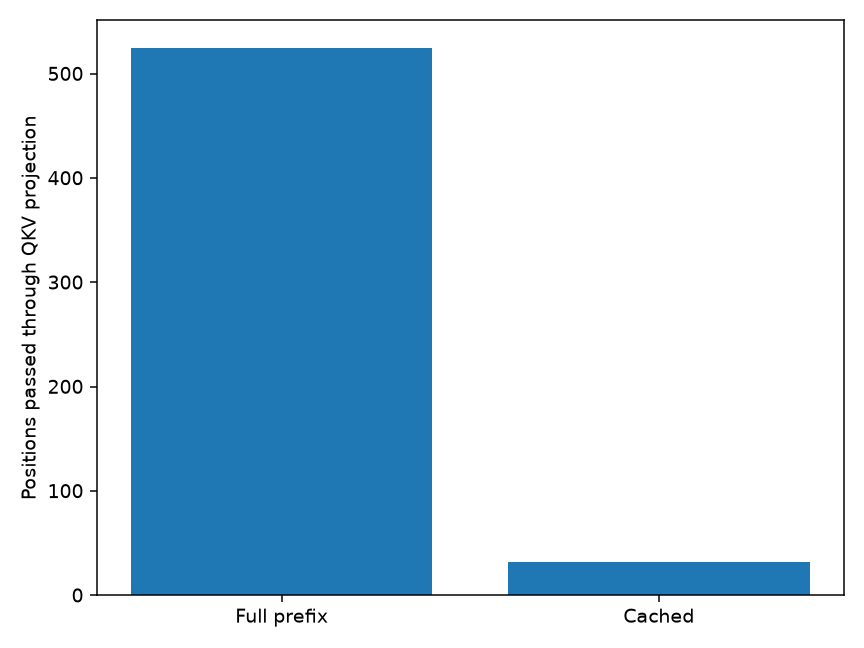

In [2]:
out, cache = cached(ids[:, :3])
with torch.no_grad():
    torch.testing.assert_close(out, model(ids[:, :3]), atol=2e-5, rtol=1e-5)
errors = []
for end in range(4, T + 1):
    out, cache = cached(ids[:, end-1:end], cache)
    with torch.no_grad():
        ref = model(ids[:, :end])[:, -1:]
    errors.append((out-ref).abs().max().item())
    torch.testing.assert_close(out, ref, atol=2e-5, rtol=1e-5)
stale, _ = cached(ids[:, T:T+1], tuple(t[:, 1:] for t in cache))
rebuilt, _ = cached(ids[:, 1:T+1])
with torch.no_grad():
    torch.testing.assert_close(rebuilt, model(ids[:, 1:T+1]), atol=2e-5, rtol=1e-5)
slide_error = (stale[:, -1] - rebuilt[:, -1]).abs().max().item()
print("Max logit error before sliding / after naive eviction:", max(errors), slide_error)
positions = [sum(range(3, T+1)), T]
print("Projected positions, full prefix / cached:", positions)
plt.bar(["Full prefix", "Cached"], positions)
plt.ylabel("Positions passed through QKV projection")
show(34, "projected_positions")
record(34, "cache_trace", errors=errors, slide_error=slide_error, positions=positions)

## Reading the result

For generation steps up to position 32, the cached path projected 32 rows in total and the full-prefix path projected 525. The largest logit difference was under 0.000004. Evicting one row and retaining the others produced a difference of about 1.02. The cached keys still encoded the earlier position numbers. Recomputing the retained window restored agreement.

Try changing only the last character of the probe. Which past key or value would have to be recomputed?